In [31]:

# Project ID: ML_73
# Project Name: Predicting Temperature in London
# Lab: Machine Learning
# Course Code: 5CIUP521

import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [32]:

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 51.5072,
    "longitude": -0.1276,
    "start_date": "2010-01-01",
    "end_date": "2025-12-31",
    "daily": (
        "temperature_2m_mean,"
        "temperature_2m_min,"
        "temperature_2m_max"
    ),
    "timezone": "Europe/London",
    "temperature_unit": "celsius"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

weather = response.json()

df = pd.DataFrame(weather["daily"])

df.rename(columns={
    "time": "date",
    "temperature_2m_mean": "mean_temp",
    "temperature_2m_min": "min_temp",
    "temperature_2m_max": "max_temp"
}, inplace=True)

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Save the raw dataset in the Colab session
df.to_csv("london_temperature.csv", index=False)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))


Dataset downloaded successfully!
Dataset shape: (5844, 4)


,date,mean_temp,min_temp,max_temp
0,2010-01-01,-0.4,-2.5,2.3
1,2010-01-02,0.6,-0.9,3.4
2,2010-01-03,-0.7,-4.2,2.1
3,2010-01-04,-3.0,-5.4,1.2
4,2010-01-05,-1.9,-4.3,1.6
5,2010-01-06,-0.4,-4.0,0.5
6,2010-01-07,-3.0,-6.7,0.0
7,2010-01-08,-2.9,-6.4,0.4
8,2010-01-09,-1.3,-3.6,0.5
9,2010-01-10,0.7,0.1,1.3


In [33]:

# CELL 3A: DATA UNDERSTANDING

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (5844, 4)

Column Names:
['date', 'mean_temp', 'min_temp', 'max_temp']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5844 entries, 0 to 5843
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       5844 non-null   datetime64[ns]
 1   mean_temp  5844 non-null   float64       
 2   min_temp   5844 non-null   float64       
 3   max_temp   5844 non-null   float64       
dtypes: datetime64[ns](1), float64(3)
memory usage: 182.8 KB

First 5 Records:


,date,mean_temp,min_temp,max_temp
0,2010-01-01,-0.4,-2.5,2.3
1,2010-01-02,0.6,-0.9,3.4
2,2010-01-03,-0.7,-4.2,2.1
3,2010-01-04,-3.0,-5.4,1.2
4,2010-01-05,-1.9,-4.3,1.6



Last 5 Records:


,date,mean_temp,min_temp,max_temp
5839,2025-12-27,5.2,2.5,7.5
5840,2025-12-28,6.4,4.0,7.1
5841,2025-12-29,5.0,3.0,6.1
5842,2025-12-30,4.3,1.2,5.8
5843,2025-12-31,0.6,-1.4,2.7



Statistical Summary:


,date,mean_temp,min_temp,max_temp
count,5844,5844.000000,5844.000000,5844.000000
mean,2017-12-31 12:00:00,11.136431,7.330390,14.776198
min,2010-01-01 00:00:00,-6.300000,-10.400000,-1.100000
25%,2013-12-31 18:00:00,7.000000,3.300000,10.200000
50%,2017-12-31 12:00:00,11.100000,7.500000,14.600000
75%,2021-12-31 06:00:00,15.600000,11.500000,19.400000
max,2025-12-31 00:00:00,29.100000,22.800000,38.000000
std,NaN,5.591527,5.232847,6.238447


In [34]:

# CELL 3B: DATA QUALITY CHECK

print("Missing values in each column:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate dates:", df["date"].duplicated().sum())

print("\nDate range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

print("\nTemperature column data types:")
display(df.dtypes)


Missing values in each column:


,0
date,0
mean_temp,0
min_temp,0
max_temp,0



Duplicate rows: 0
Duplicate dates: 0

Date range:
Start: 2010-01-01 00:00:00
End: 2025-12-31 00:00:00

Temperature column data types:


,0
date,datetime64[ns]
mean_temp,float64
min_temp,float64
max_temp,float64


In [35]:

# CELL 3C: DATA CLEANING

df = df.drop_duplicates(subset="date")
df = df.sort_values("date").reset_index(drop=True)

temperature_cols = ["mean_temp", "min_temp", "max_temp"]

for col in temperature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Treat impossible values as missing, if any
df[temperature_cols] = df[temperature_cols].replace(
    [np.inf, -np.inf], np.nan
)

# The target must be available for supervised training
df = df.dropna(subset=["mean_temp"]).reset_index(drop=True)

print("Cleaning completed.")
print("Cleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
display(df.isnull().sum())

display(df.head())



Cleaning completed.
Cleaned dataset shape: (5844, 4)

Missing values after cleaning:


,0
date,0
mean_temp,0
min_temp,0
max_temp,0


,date,mean_temp,min_temp,max_temp
0,2010-01-01,-0.4,-2.5,2.3
1,2010-01-02,0.6,-0.9,3.4
2,2010-01-03,-0.7,-4.2,2.1
3,2010-01-04,-3.0,-5.4,1.2
4,2010-01-05,-1.9,-4.3,1.6


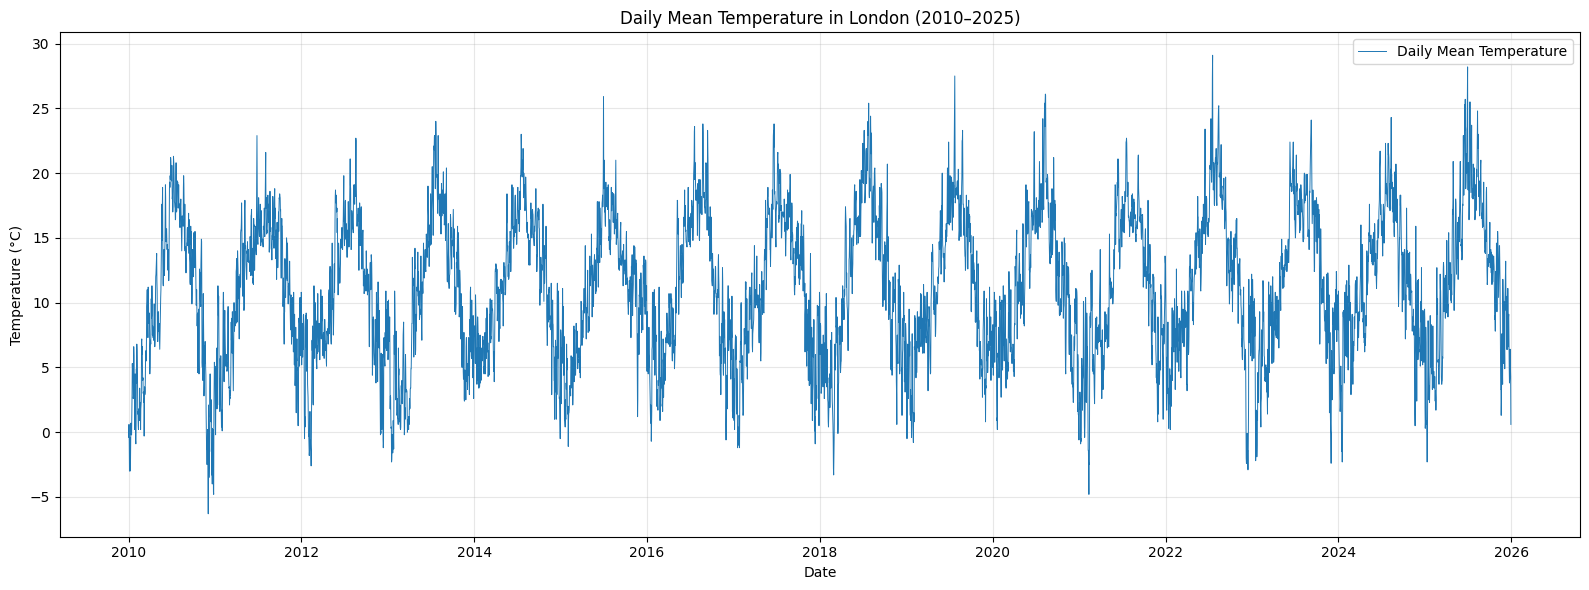

In [36]:

# CELL 3D: TEMPERATURE TREND

plt.figure(figsize=(16, 6))

plt.plot(
    df["date"],
    df["mean_temp"],
    linewidth=0.7,
    label="Daily Mean Temperature"
)

plt.title("Daily Mean Temperature in London (2010–2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


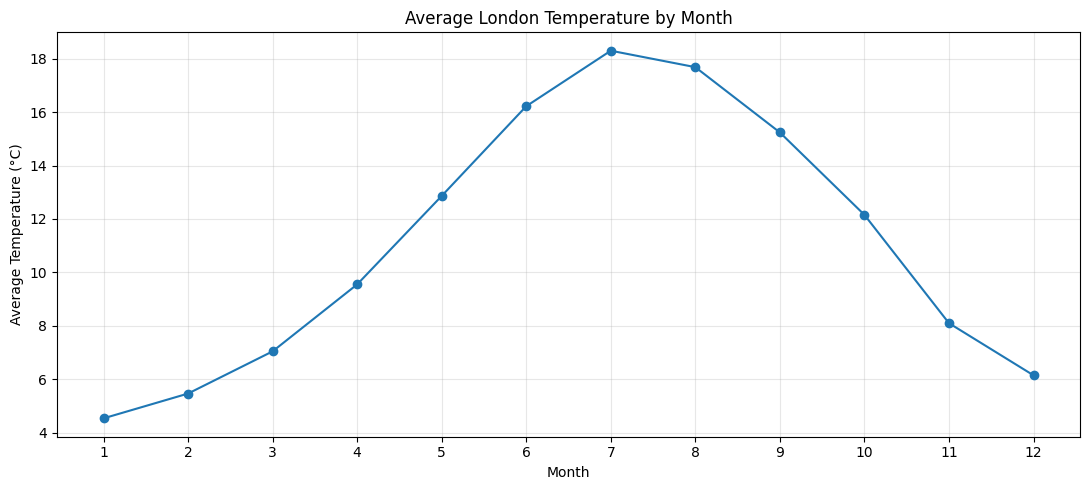

Monthly average temperatures:


,mean_temp
month,
1,4.53
2,5.46
3,7.04
4,9.55
5,12.86
6,16.22
7,18.30
8,17.69
9,15.24


In [37]:

# CELL 3E: MONTHLY TEMPERATURE PATTERN

df["month"] = df["date"].dt.month

monthly_temp = df.groupby("month")["mean_temp"].mean()

plt.figure(figsize=(11, 5))
plt.plot(monthly_temp.index, monthly_temp.values, marker="o")

plt.title("Average London Temperature by Month")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Monthly average temperatures:")
display(monthly_temp.round(2))


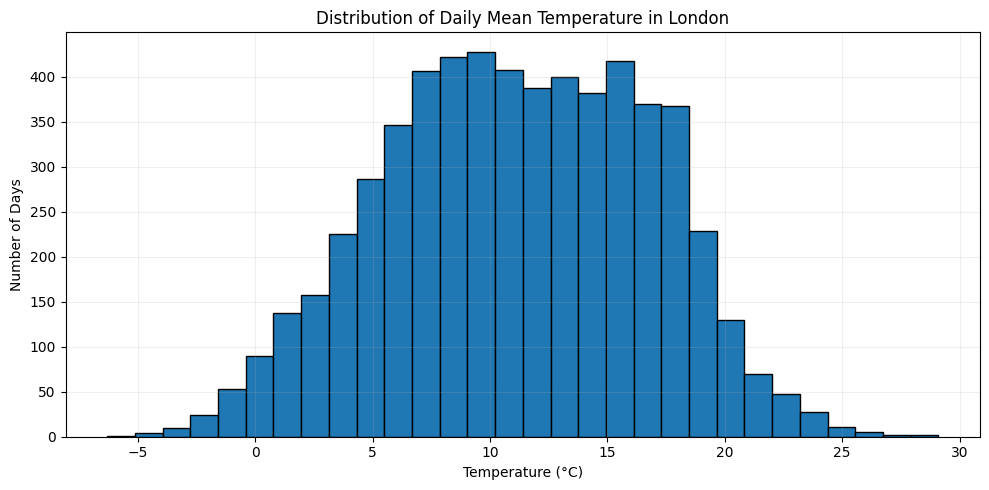

Mean temperature: 11.14 °C
Minimum recorded daily mean: -6.3 °C
Maximum recorded daily mean: 29.1 °C


In [38]:

# CELL 3F: TEMPERATURE DISTRIBUTIONS

plt.figure(figsize=(10, 5))

plt.hist(
    df["mean_temp"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Daily Mean Temperature in London")
plt.xlabel("Temperature (°C)")
plt.ylabel("Number of Days")
plt.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print("Mean temperature:", round(df["mean_temp"].mean(), 2), "°C")
print("Minimum recorded daily mean:", round(df["mean_temp"].min(), 2), "°C")
print("Maximum recorded daily mean:", round(df["mean_temp"].max(), 2), "°C")


In [39]:

# CELL 4A: TIME-BASED FEATURE ENGINEERING

# Create a separate working dataset
data = df.copy()

# Calendar features
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month
data["day"] = data["date"].dt.day
data["day_of_week"] = data["date"].dt.dayofweek
data["day_of_year"] = data["date"].dt.dayofyear

# Cyclical encoding for yearly seasonality
data["year_sin"] = np.sin(
    2 * np.pi * data["day_of_year"] / 365.25
)

data["year_cos"] = np.cos(
    2 * np.pi * data["day_of_year"] / 365.25
)

display(data.head())


,date,mean_temp,min_temp,max_temp,month,year,day,day_of_week,day_of_year,year_sin,year_cos
0,2010-01-01,-0.4,-2.5,2.3,1,2010,1,4,1,0.017202,0.999852
1,2010-01-02,0.6,-0.9,3.4,1,2010,2,5,2,0.034398,0.999408
2,2010-01-03,-0.7,-4.2,2.1,1,2010,3,6,3,0.051584,0.998669
3,2010-01-04,-3.0,-5.4,1.2,1,2010,4,0,4,0.068755,0.997634
4,2010-01-05,-1.9,-4.3,1.6,1,2010,5,1,5,0.085906,0.996303


In [40]:

# CELL 4B: LAG FEATURES

# Previous days' mean temperatures
lag_days = [1, 2, 3, 7, 14, 30, 365]

for lag in lag_days:
    data[f"lag_{lag}"] = data["mean_temp"].shift(lag)

# Rolling averages using only previous days
data["rolling_mean_7"] = (
    data["mean_temp"].shift(1).rolling(window=7).mean()
)

data["rolling_mean_30"] = (
    data["mean_temp"].shift(1).rolling(window=30).mean()
)

# Display the newly created features
display(
    data[
        [
            "date",
            "mean_temp",
            "lag_1",
            "lag_7",
            "lag_30",
            "lag_365",
            "rolling_mean_7",
            "rolling_mean_30"
        ]
    ].tail(10)
)


,date,mean_temp,lag_1,lag_7,lag_30,lag_365,rolling_mean_7,rolling_mean_30
5834,2025-12-22,9.1,8.9,10.5,5.6,5.6,8.785714,8.440000
5835,2025-12-23,6.8,9.1,9.5,7.6,5.2,8.585714,8.556667
5836,2025-12-24,4.9,6.8,6.4,5.6,9.4,8.200000,8.530000
5837,2025-12-25,3.8,4.9,11.1,5.0,9.3,7.985714,8.506667
5838,2025-12-26,4.2,3.8,8.5,3.7,7.4,6.942857,8.466667
5839,2025-12-27,5.2,4.2,6.6,11.8,6.5,6.328571,8.483333
5840,2025-12-28,6.4,5.2,8.9,10.5,5.4,6.128571,8.263333
5841,2025-12-29,5.0,6.4,9.1,8.9,5.8,5.771429,8.126667
5842,2025-12-30,4.3,5.0,6.8,5.3,7.4,5.185714,7.996667
5843,2025-12-31,0.6,4.3,4.9,10.1,9.5,4.828571,7.963333


In [41]:

# CELL 4C: FINAL FEATURE DATASET

feature_cols = [
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "year_sin",
    "year_cos",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "lag_30",
    "lag_365",
    "rolling_mean_7",
    "rolling_mean_30"
]

# Remove rows with missing model features or target
data = data.dropna(
    subset=feature_cols + ["mean_temp"]
).reset_index(drop=True)

print("Final modelling dataset shape:", data.shape)

print("\nFeatures used by the models:")
print(feature_cols)

print("\nMissing values in modelling features:")
display(data[feature_cols].isnull().sum())

display(data.head())


Final modelling dataset shape: (5479, 20)

Features used by the models:
['year', 'month', 'day', 'day_of_week', 'day_of_year', 'year_sin', 'year_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_30', 'lag_365', 'rolling_mean_7', 'rolling_mean_30']

Missing values in modelling features:


,0
year,0
month,0
day,0
day_of_week,0
day_of_year,0
year_sin,0
year_cos,0
lag_1,0
lag_2,0
lag_3,0


,date,mean_temp,min_temp,max_temp,month,year,day,day_of_week,day_of_year,year_sin,year_cos,lag_1,lag_2,lag_3,lag_7,lag_14,lag_30,lag_365,rolling_mean_7,rolling_mean_30
0,2011-01-01,4.5,2.5,6.0,1,2011,1,5,1,0.017202,0.999852,4.2,4.8,5.4,-4.6,-2.3,-2.2,-0.4,1.542857,-0.033333
1,2011-01-02,0.6,-2.4,2.8,1,2011,2,6,2,0.034398,0.999408,4.5,4.2,4.8,-4.8,-2.6,-6.3,0.6,2.842857,0.190000
2,2011-01-03,-0.2,-2.4,2.2,1,2011,3,0,3,0.051584,0.998669,0.6,4.5,4.2,1.8,-4.0,2.1,-0.7,3.614286,0.420000
3,2011-01-04,2.3,-0.1,5.0,1,2011,4,1,4,0.068755,0.997634,-0.2,0.6,4.5,4.0,0.3,0.8,-3.0,3.328571,0.343333
4,2011-01-05,5.1,3.4,6.6,1,2011,5,2,5,0.085906,0.996303,2.3,-0.2,0.6,5.4,-0.1,-3.5,-1.9,3.085714,0.393333


In [42]:

# CELL 4D: CHRONOLOGICAL TRAIN-TEST SPLIT

split_index = int(len(data) * 0.80)

train_data = data.iloc[:split_index].copy()
test_data = data.iloc[split_index:].copy()

X_train = train_data[feature_cols]
y_train = train_data["mean_temp"]

X_test = test_data[feature_cols]
y_test = test_data["mean_temp"]

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

print("\nTraining period:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nTesting period:")
print(test_data["date"].min(), "to", test_data["date"].max())


Training observations: 4383
Testing observations: 1096

Training period:
2011-01-01 00:00:00 to 2022-12-31 00:00:00

Testing period:
2023-01-01 00:00:00 to 2025-12-31 00:00:00


In [43]:

# CELL 5A: MODEL TRAINING

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully!")

print("\nAll regression models are trained.")


Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!

All regression models are trained.


In [44]:

# CELL 5B: PREDICTIONS

predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)

print("Predictions generated successfully!")

# Compare the first 10 predictions
comparison = pd.DataFrame({
    "Date": test_data["date"].values,
    "Actual Temperature": y_test.values,
    "Linear Regression": predictions["Linear Regression"],
    "Decision Tree": predictions["Decision Tree"],
    "Random Forest": predictions["Random Forest"]
})

display(comparison.head(10).round(2))


Predictions generated successfully!


,Date,Actual Temperature,Linear Regression,Decision Tree,Random Forest
0,2023-01-01,10.2,10.46,14.00,11.13
1,2023-01-02,5.5,8.45,6.50,7.69
2,2023-01-03,8.3,4.95,7.81,6.48
3,2023-01-04,11.8,8.14,7.22,7.86
4,2023-01-05,10.5,10.39,9.93,10.69
5,2023-01-06,9.6,8.87,8.94,8.22
6,2023-01-07,10.1,8.52,7.80,8.24
7,2023-01-08,7.2,8.97,7.20,8.26
8,2023-01-09,5.7,6.45,6.46,6.31
9,2023-01-10,8.6,5.70,5.70,6.27


In [45]:

# CELL 5C: MODEL EVALUATION

results = []

for name, pred in predictions.items():

    mae = mean_absolute_error(y_test, pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, pred)
    )

    r2 = r2_score(y_test, pred)

    results.append({
        "Model": name,
        "MAE (°C)": mae,
        "RMSE (°C)": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE (°C)"
).reset_index(drop=True)

display(results_df.round(4))


,Model,MAE (°C),RMSE (°C),R2 Score
0,Linear Regression,1.4179,1.8445,0.8898
1,Random Forest,1.4801,1.8989,0.8832
2,Decision Tree,1.7838,2.2876,0.8304


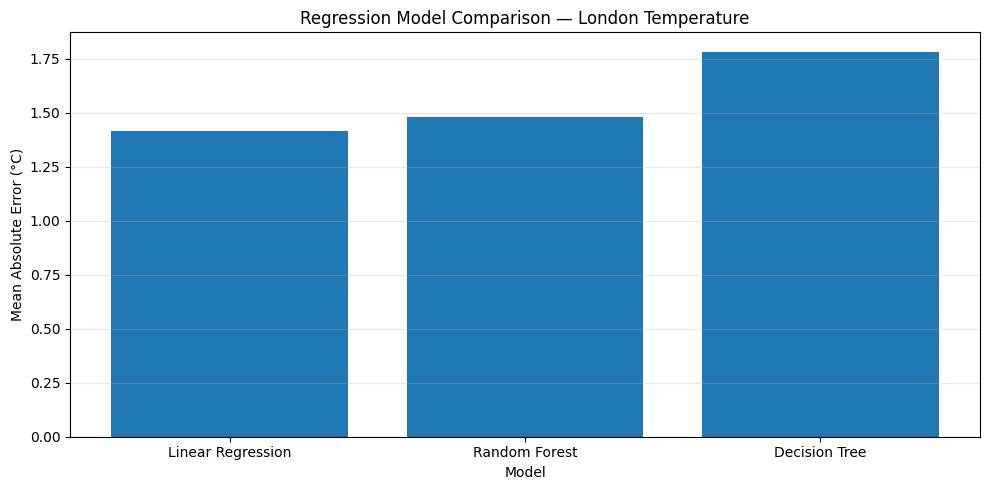

In [46]:

# CELL 5D: MODEL COMPARISON GRAPH

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["MAE (°C)"]
)

plt.title("Regression Model Comparison — London Temperature")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (°C)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


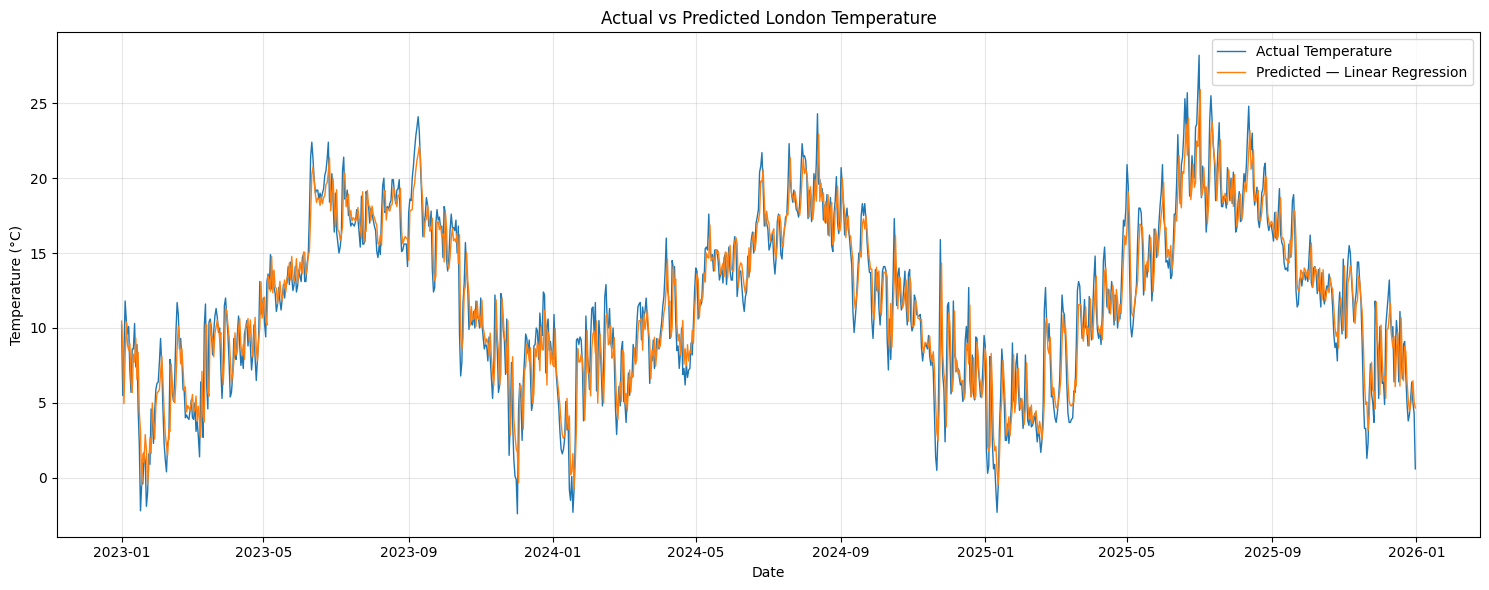

Best model by test MAE: Linear Regression


In [47]:

# CELL 5E: ACTUAL VS PREDICTED

best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]

plt.figure(figsize=(15, 6))

plt.plot(
    test_data["date"],
    y_test,
    label="Actual Temperature",
    linewidth=1
)

plt.plot(
    test_data["date"],
    best_predictions,
    label=f"Predicted — {best_model_name}",
    linewidth=1
)

plt.title("Actual vs Predicted London Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Best model by test MAE:", best_model_name)


In [48]:

# CELL 6A: SEASONAL NAIVE BASELINE

seasonal_naive_predictions = test_data["lag_365"].to_numpy()

baseline_mae = mean_absolute_error(
    y_test, seasonal_naive_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, seasonal_naive_predictions)
)

baseline_r2 = r2_score(
    y_test, seasonal_naive_predictions
)

baseline_result = pd.DataFrame([{
    "Model": "Seasonal Naive (365-day lag)",
    "MAE (°C)": baseline_mae,
    "RMSE (°C)": baseline_rmse,
    "R2 Score": baseline_r2
}])

print("Seasonal Naive Baseline Results:")
display(baseline_result.round(4))



Seasonal Naive Baseline Results:


,Model,MAE (°C),RMSE (°C),R2 Score
0,Seasonal Naive (365-day lag),3.1528,3.9729,0.4886


In [49]:

# CELL 6B: FINAL MODEL COMPARISON

final_results = pd.concat(
    [results_df, baseline_result],
    ignore_index=True
)

final_results = final_results.sort_values(
    "MAE (°C)"
).reset_index(drop=True)

display(final_results.round(4))

final_results.to_csv(
    "ML_73_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")


,Model,MAE (°C),RMSE (°C),R2 Score
0,Linear Regression,1.4179,1.8445,0.8898
1,Random Forest,1.4801,1.8989,0.8832
2,Decision Tree,1.7838,2.2876,0.8304
3,Seasonal Naive (365-day lag),3.1528,3.9729,0.4886


Model comparison saved successfully.


,Feature,Importance
0,lag_1,0.908765
1,year_cos,0.008754
2,rolling_mean_7,0.008387
3,rolling_mean_30,0.008272
4,lag_2,0.008203
5,lag_365,0.007961
6,lag_7,0.007397
7,lag_30,0.006911
8,lag_14,0.006663
9,lag_3,0.006383


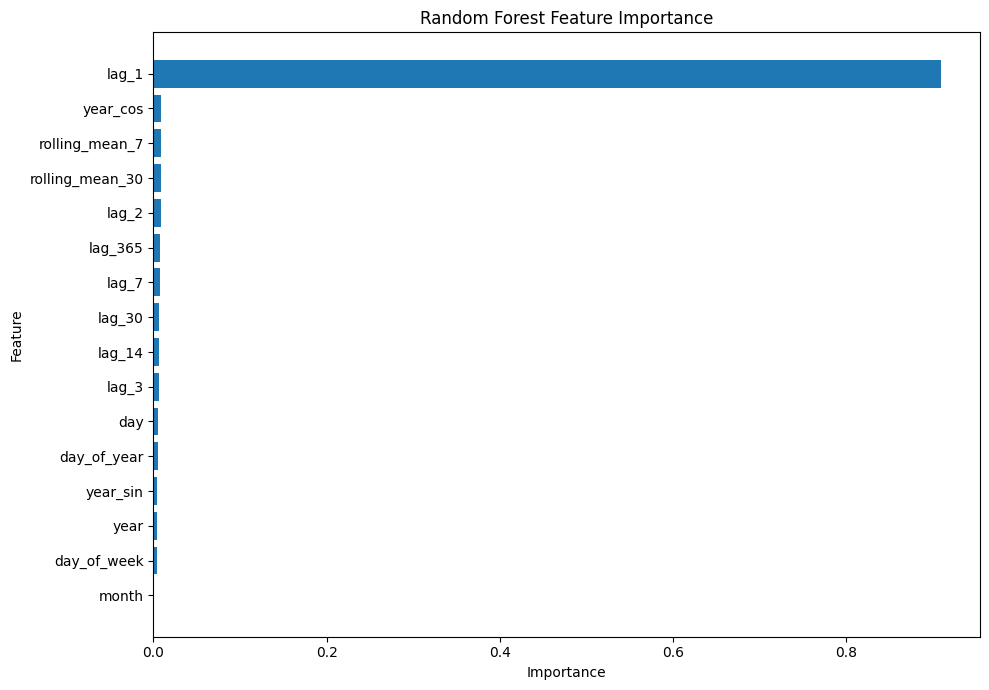

In [50]:

# CELL 6C: RANDOM FOREST FEATURE IMPORTANCE

rf_model = models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

display(importance_df)

plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [51]:


# CELL 6D: FINAL PREDICTION REPORT

prediction_report = pd.DataFrame({
    "date": test_data["date"].to_numpy(),
    "actual_temperature": y_test.to_numpy(),
    "linear_regression": predictions["Linear Regression"],
    "decision_tree": predictions["Decision Tree"],
    "random_forest": predictions["Random Forest"],
    "seasonal_naive": seasonal_naive_predictions
})

prediction_report = prediction_report.round(3)

display(prediction_report.head(15))

prediction_report.to_csv(
    "ML_73_temperature_predictions.csv",
    index=False
)

print("Prediction report saved successfully.")



,date,actual_temperature,linear_regression,decision_tree,random_forest,seasonal_naive
0,2023-01-01,10.2,10.463,14.000,11.133,13.0
1,2023-01-02,5.5,8.453,6.500,7.692,10.9
2,2023-01-03,8.3,4.954,7.813,6.485,8.6
3,2023-01-04,11.8,8.138,7.217,7.856,4.5
4,2023-01-05,10.5,10.390,9.929,10.694,1.9
5,2023-01-06,9.6,8.867,8.940,8.222,1.7
6,2023-01-07,10.1,8.520,7.800,8.243,3.6
7,2023-01-08,7.2,8.968,7.200,8.265,5.8
8,2023-01-09,5.7,6.447,6.460,6.307,3.0
9,2023-01-10,8.6,5.698,5.700,6.274,5.1


Prediction report saved successfully.


In [52]:

# CELL 6E: DOWNLOAD OUTPUT FILES

from google.colab import files

files.download("ML_73_model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:

from google.colab import files

files.download("ML_73_temperature_predictions.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:

# ============================================================
# CELL 7A: WALK-FORWARD VALIDATION
# Project: ML_73 - Predicting Temperature in London
# ============================================================

from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

# Ensure observations are in chronological order
validation_data = data.sort_values("date").reset_index(drop=True)

X = validation_data[feature_cols]
y = validation_data["mean_temp"]

# Five chronological validation folds
tscv = TimeSeriesSplit(n_splits=5)

model_templates = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    tscv.split(X), start=1
):

    X_train_fold = X.iloc[train_idx]
    y_train_fold = y.iloc[train_idx]

    X_test_fold = X.iloc[test_idx]
    y_test_fold = y.iloc[test_idx]

    print(f"\nProcessing Fold {fold}")
    print(
        "Training:",
        validation_data["date"].iloc[train_idx[0]].date(),
        "to",
        validation_data["date"].iloc[train_idx[-1]].date()
    )
    print(
        "Testing:",
        validation_data["date"].iloc[test_idx[0]].date(),
        "to",
        validation_data["date"].iloc[test_idx[-1]].date()
    )

    # Evaluate each regression model
    for name, template in model_templates.items():

        model = clone(template)
        model.fit(X_train_fold, y_train_fold)

        pred = model.predict(X_test_fold)

        fold_results.append({
            "Fold": fold,
            "Model": name,
            "MAE": mean_absolute_error(y_test_fold, pred),
            "RMSE": np.sqrt(
                mean_squared_error(y_test_fold, pred)
            ),
            "R2": r2_score(y_test_fold, pred)
        })

    # Seasonal naive benchmark
    baseline_pred = validation_data[
        "lag_365"
    ].iloc[test_idx].to_numpy()

    fold_results.append({
        "Fold": fold,
        "Model": "Seasonal Naive",
        "MAE": mean_absolute_error(
            y_test_fold, baseline_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_fold, baseline_pred
            )
        ),
        "R2": r2_score(y_test_fold, baseline_pred)
    })

print("\nWalk-forward validation completed!")



Processing Fold 1
Training: 2011-01-01 to 2013-07-02
Testing: 2013-07-03 to 2016-01-01

Processing Fold 2
Training: 2011-01-01 to 2016-01-01
Testing: 2016-01-02 to 2018-07-02

Processing Fold 3
Training: 2011-01-01 to 2018-07-02
Testing: 2018-07-03 to 2020-12-31

Processing Fold 4
Training: 2011-01-01 to 2020-12-31
Testing: 2021-01-01 to 2023-07-02

Processing Fold 5
Training: 2011-01-01 to 2023-07-02
Testing: 2023-07-03 to 2025-12-31

Walk-forward validation completed!


In [55]:

# CELL 7B: AVERAGE PERFORMANCE ACROSS FOLDS

walk_forward_df = pd.DataFrame(fold_results)

walk_forward_summary = (
    walk_forward_df
    .groupby("Model")
    .agg(
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_R2=("R2", "mean")
    )
    .sort_values("Mean_MAE")
    .reset_index()
)

print("Walk-forward validation results:")
display(walk_forward_summary.round(4))

walk_forward_df.to_csv(
    "ML_73_walk_forward_fold_results.csv",
    index=False
)

walk_forward_summary.to_csv(
    "ML_73_walk_forward_summary.csv",
    index=False
)

print("Both validation CSV files have been saved.")


Walk-forward validation results:


,Model,Mean_MAE,Std_MAE,Mean_RMSE,Mean_R2
0,Linear Regression,1.4465,0.1007,1.8708,0.8809
1,Random Forest,1.4507,0.0602,1.8723,0.8825
2,Decision Tree,1.7917,0.0598,2.2965,0.8227
3,Seasonal Naive,3.1334,0.0837,3.9499,0.4776


Both validation CSV files have been saved.


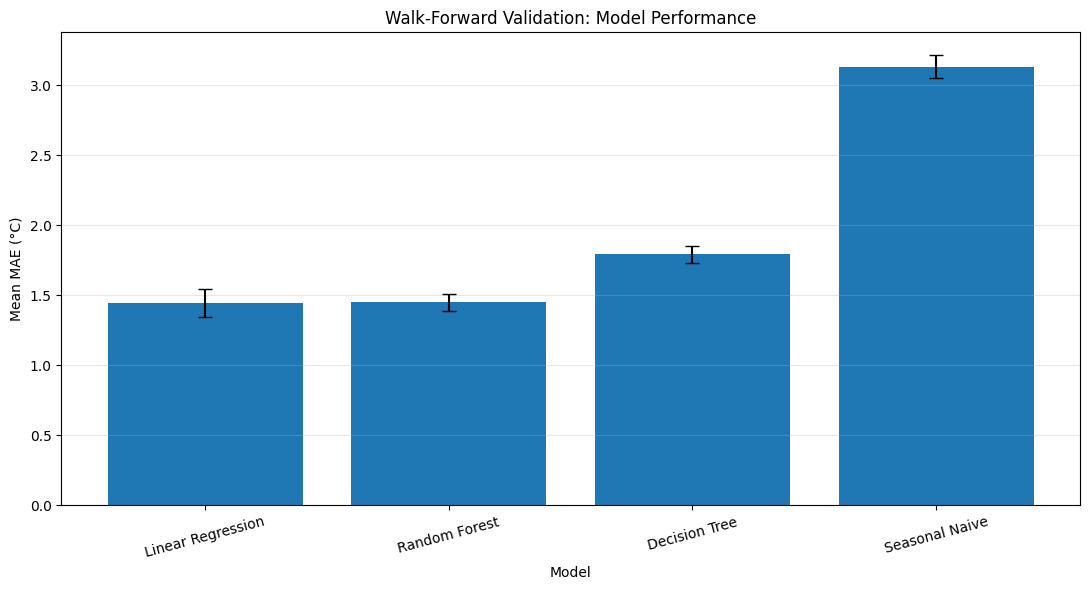

In [56]:

# CELL 8: WALK-FORWARD VALIDATION VISUALIZATION

plt.figure(figsize=(11, 6))

plt.bar(
    walk_forward_summary["Model"],
    walk_forward_summary["Mean_MAE"],
    yerr=walk_forward_summary["Std_MAE"],
    capsize=5
)

plt.title("Walk-Forward Validation: Model Performance")
plt.xlabel("Model")
plt.ylabel("Mean MAE (°C)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ML_73_walk_forward_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [57]:

from google.colab import files

files.download("ML_73_walk_forward_summary.csv")
files.download("ML_73_walk_forward_fold_results.csv")
files.download("ML_73_walk_forward_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:

# FINAL DATA QUALITY VERIFICATION

df = df.sort_values("date").reset_index(drop=True)

expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(
    pd.DatetimeIndex(df["date"])
)

print("Dataset rows:", len(df))
print("Duplicate dates:", df["date"].duplicated().sum())
print("Missing calendar dates:", len(missing_dates))
print("Missing mean temperatures:", df["mean_temp"].isna().sum())
print("Date range:", df["date"].min(), "to", df["date"].max())

if len(missing_dates) == 0:
    print("PASS: Daily dates are continuous.")
else:
    print("CHECK: Missing dates detected.")
    print("First missing dates:", missing_dates[:10].tolist())


Dataset rows: 5844
Duplicate dates: 0
Missing calendar dates: 0
Missing mean temperatures: 0
Date range: 2010-01-01 00:00:00 to 2025-12-31 00:00:00
PASS: Daily dates are continuous.


In [59]:

# =====================================================
# ML_73: PREPARE FILES FOR GITHUB UPLOAD
# =====================================================

import os
import joblib
import shutil
import matplotlib.pyplot as plt

# Create project folders
os.makedirs("ML_73_GitHub/data", exist_ok=True)
os.makedirs("ML_73_GitHub/models", exist_ok=True)
os.makedirs("ML_73_GitHub/outputs", exist_ok=True)

BASE = "ML_73_GitHub"

# 1. Save original dataset
df.to_csv(
    f"{BASE}/data/london_temperature.csv",
    index=False
)

# 2. Train and save final Random Forest model
final_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

final_model.fit(data[feature_cols], data["mean_temp"])

joblib.dump(
    final_model,
    f"{BASE}/models/random_forest_model.pkl"
)

joblib.dump(
    feature_cols,
    f"{BASE}/models/feature_columns.pkl"
)

# 3. Save evaluation results
walk_forward_summary.to_csv(
    f"{BASE}/outputs/walk_forward_summary.csv",
    index=False
)

walk_forward_df.to_csv(
    f"{BASE}/outputs/walk_forward_fold_results.csv",
    index=False
)

final_results.to_csv(
    f"{BASE}/outputs/model_comparison.csv",
    index=False
)

prediction_report.to_csv(
    f"{BASE}/outputs/temperature_predictions.csv",
    index=False
)

# 4. Save temperature trend graph
plt.figure(figsize=(14, 5))
plt.plot(df["date"], df["mean_temp"])
plt.title("Daily Mean Temperature in London")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.tight_layout()
plt.savefig(f"{BASE}/outputs/temperature_trend.png", dpi=150)
plt.close()

# 5. Save monthly seasonality graph
monthly = df.groupby(
    df["date"].dt.month
)["mean_temp"].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Average Temperature")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{BASE}/outputs/monthly_seasonality.png", dpi=150)
plt.close()

# 6. Save walk-forward comparison graph
plt.figure(figsize=(10, 5))
plt.bar(
    walk_forward_summary["Model"],
    walk_forward_summary["Mean_MAE"],
    yerr=walk_forward_summary["Std_MAE"],
    capsize=4
)
plt.title("Walk-Forward Model Comparison")
plt.ylabel("Mean MAE (°C)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(f"{BASE}/outputs/walk_forward_comparison.png", dpi=150)
plt.close()

# 7. Save feature importance
importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": final_model.feature_importances_
}).sort_values("Importance", ascending=False)

importance.to_csv(
    f"{BASE}/outputs/feature_importance.csv",
    index=False
)

plt.figure(figsize=(10, 6))
plt.barh(
    importance["Feature"][::-1],
    importance["Importance"][::-1]
)
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.savefig(f"{BASE}/outputs/feature_importance.png", dpi=150)
plt.close()

# 8. Create requirements file
with open(f"{BASE}/requirements.txt", "w") as f:
    f.write(
        "pandas\nnumpy\nmatplotlib\n"
        "scikit-learn\nstreamlit\njoblib\nrequests\n"
    )

# 9. Create Git ignore file
with open(f"{BASE}/.gitignore", "w") as f:
    f.write(
        "__pycache__/\n"
        ".ipynb_checkpoints/\n"
        "*.pyc\n"
        ".env\n"
    )

# 10. Create ZIP
shutil.make_archive(
    "ML_73_GitHub_Assets",
    "zip",
    root_dir=".",
    base_dir=BASE
)

print("PROJECT EXPORT COMPLETED!")
print("ZIP: ML_73_GitHub_Assets.zip")
print("Contains dataset, models, graphs, results and requirements.")


PROJECT EXPORT COMPLETED!
ZIP: ML_73_GitHub_Assets.zip
Contains dataset, models, graphs, results and requirements.
